# Visualize Last-Layer Attention-Graph Threshold Robustness

This Visualize notebook presents last-layer attention-graph threshold robustness for representative constant and chaotic logistic-map sequences at $N = 500$ using Llama-3.2-3B, as presented under **Attention-Induced Token Graphs: Construction and Visualization Robustness** in the appendix.

The columns apply display thresholds $\kappa/N$ for $\kappa \in \{2,4,8\}$ while preserving the cached 100-iteration FR coordinates. The main token-graph visualizations use $\kappa = 2.5$; the qualitative organization remains stable across the tested thresholds.

The included caches are the `Constant 500` and `Logistic r=4.0` subset of the graph data generated by `Main/Attention-induced-token-graphs/Across-dynamical-complexity/Generate-token-graphs-across-dynamical-complexity.ipynb`.

Import dependencies and define the 500-token analysis window and threshold grid.

In [ ]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

# Analysis window
REFERENCE_CONTEXT_TOKENS = 1000
ANALYSIS_CONTEXT_TOKENS = 500
CONTEXT_FRAC = ANALYSIS_CONTEXT_TOKENS / REFERENCE_CONTEXT_TOKENS
PROCESSED_DATA_DIR = Path('./processed_graph_data')
FIGURE_OUTPUT_DIR = Path('figure')

# Representative inputs and kappa values for the kappa/N display threshold
ROBUSTNESS_DATA_ORDER = [
    'Constant 500',
    'Logistic r=4.0',
]
THRESHOLD_FACTORS = np.array([2, 4, 8], dtype=int)

# Edge and node drawing style
RGB_GRAPH_EDGE_BASE_GRAY = 0.15
RGB_GRAPH_EDGE_ALPHA_MIN = 0.06
RGB_GRAPH_EDGE_ALPHA_SPAN = 0.52
RGB_GRAPH_EDGE_ALPHA_GAMMA = 0.85
RGB_GRAPH_EDGE_LW_MIN = 0.35
RGB_GRAPH_EDGE_LW_SPAN = 1.95
RGB_GRAPH_EDGE_LW_GAMMA = 0.90
RGB_GRAPH_NODE_SIZE = 18
RGB_GRAPH_DELIMITER_SIZE = 24
RGB_GRAPH_NODE_SIZE_FLOOR = 8
RGB_GRAPH_DELIMITER_SIZE_FLOOR = 10
RGB_GRAPH_DRAW_TOKEN_ORDER_TRACE = False
RGB_GRAPH_MAX_EDGES_DRAW = None
RGB_GRAPH_EDGE_STYLE_BINS = 20
LABEL_TOKEN_MARKERS = False
TOKEN_MARKER_LABELS_ONE_BASED = np.array([1, 100, 200, 300, 400, ANALYSIS_CONTEXT_TOKENS], dtype=int)
RGB_GRAPH_X_MARGIN = 0.01
RGB_GRAPH_Y_MARGIN = 0.06

# Figure layout
FIGURE_SIZE = (8.2, 6.1)
DISPLAY_DPI = 150
PDF_DPI = 300
SUBPLOT_ADJUST = dict(left=0.075, right=0.995, bottom=0.105, top=0.925, wspace=0.4, hspace=0.06)
SAVEFIG_PAD_INCHES = 0.03
PANEL_LABEL_FONT_SIZE = 14.5
COLUMN_TITLE_Y_OFFSET = 0.016
ROW_LABEL_X = 0.026

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['figure.dpi'] = DISPLAY_DPI
plt.rcParams['savefig.dpi'] = PDF_DPI

Define panel labels, the exact cache schema, and validation helpers for the two included archives.

In [2]:
DATA_TITLE_OVERRIDES = {
    'Constant 500': 'Constant sequence',
}

DATA_TITLE_SUFFIXES = {
    'Logistic r=4.0': 'chaotic',
}

# Match the complete schema written by the main graph-generation workflow
GRAPH_DATA_ARRAY_KEYS = (
    'layer_indices',
    'Wbar',
    'layout_positions',
    'svd_projection_coords',
    'svd_cumulative_energy_ratio',
    'is_delimiter',
)


def panel_title(data_name):
    data_name = str(data_name)
    title = DATA_TITLE_OVERRIDES.get(data_name, data_name)
    suffix = DATA_TITLE_SUFFIXES.get(data_name)
    return f'{title} ({suffix})' if suffix else title


def context_fraction_label(frac):
    # Preserve the generation workflow's context50 label for the 500/1000 analysis fraction
    pct = int(round(100 * float(frac)))
    return f'context{pct}'


def safe_data_stem(data_name, frac):
    name = str(data_name).replace('=', '_').replace('.', '_')
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return f'{name}_{context_fraction_label(frac)}'


def graph_data_path(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    return Path(data_dir) / f'{safe_data_stem(data_name, frac)}_graph_data.npz'


# Require the exact schema to catch stale or incompatible caches
def load_processed_graph_data(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as npz:
        processed_data = {key: npz[key] for key in npz.files}

    missing = [key for key in GRAPH_DATA_ARRAY_KEYS if key not in processed_data]
    if missing:
        raise KeyError(f'{path} is missing required arrays: {missing}')
    extra = sorted(set(processed_data) - set(GRAPH_DATA_ARRAY_KEYS))
    if extra:
        raise KeyError(f'{path} contains unexpected arrays: {extra}')
    return processed_data


# Verify both bundled archives before plotting
def check_processed_graph_data(data_names=ROBUSTNESS_DATA_ORDER, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    missing = []
    invalid = []
    for data_name in data_names:
        path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
        if not path.exists():
            missing.append(path)
            continue
        try:
            load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        except (OSError, KeyError, ValueError) as exc:
            invalid.append((path, exc))

    if missing:
        raise FileNotFoundError('Missing processed graph data:\n' + '\n'.join(str(path) for path in missing))
    if invalid:
        details = '\n'.join(f'{path}: {exc}' for path, exc in invalid)
        raise ValueError('Invalid processed graph data:\n' + details)

Define uniform-baseline thresholding, hidden-state color scaling, optional token markers, and graph-rendering helpers.

In [3]:
# Convert kappa to the absolute display threshold kappa/N
def edge_weight_threshold_from_uniform(n_nodes, factor):
    n_nodes = int(n_nodes)
    if n_nodes <= 0:
        return float('inf')
    return float(factor) / float(n_nodes)


# Map the first three cached hidden-state SVD coordinates independently to RGB
def _minmax_scale_rgb_channels(coords, fill_value=0.5, eps=1e-12):
    coords = np.asarray(coords, dtype=float)
    if coords.ndim == 1:
        coords = coords[:, None]
    if coords.ndim != 2:
        raise ValueError('coords must be 2D (num_tokens x num_components)')

    n = coords.shape[0]
    rgb = np.full((n, 3), float(fill_value), dtype=float)
    if n == 0:
        return rgb

    for k in range(3):
        if coords.shape[1] <= k:
            continue
        col = np.asarray(coords[:, k], dtype=float)
        finite = np.isfinite(col)
        if not np.any(finite):
            continue
        cmin = float(np.min(col[finite]))
        cmax = float(np.max(col[finite]))
        if (cmax - cmin) <= float(eps):
            rgb[finite, k] = float(fill_value)
        else:
            rgb[finite, k] = (col[finite] - cmin) / (cmax - cmin)

    rgb[~np.isfinite(rgb)] = float(fill_value)
    return np.clip(rgb, 0.0, 1.0)


# Select undirected upper-triangle edges above the requested threshold
def select_top_edges(W, max_edges=None, threshold=None, threshold_factor=1.0):
    W = np.asarray(W, dtype=float).copy()
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError('W must be square')

    n = W.shape[0]
    if n < 2:
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    W[~np.isfinite(W)] = 0.0
    np.fill_diagonal(W, 0.0)
    iu = np.triu_indices(n, k=1)
    w = W[iu]

    edge_threshold = edge_weight_threshold_from_uniform(n, threshold_factor) if threshold is None else float(threshold)
    pos_mask = np.isfinite(w) & (w > edge_threshold)
    if not np.any(pos_mask):
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    pos_idx = np.nonzero(pos_mask)[0]
    w_pos = w[pos_mask]

    if max_edges is None:
        chosen = pos_idx
    else:
        k = min(int(max_edges), w_pos.size)
        if k <= 0:
            return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)
        if k < w_pos.size:
            top_local = np.argpartition(w_pos, -k)[-k:]
            chosen = pos_idx[top_local]
        else:
            chosen = pos_idx

    order = np.argsort(w[chosen])[::-1]
    chosen = chosen[order]
    return iu[0][chosen], iu[1][chosen], w[chosen]


# Convert optional one-based display token labels to array indices
def token_marker_indices_and_labels(n, marker_labels_one_based=TOKEN_MARKER_LABELS_ONE_BASED):
    marker_labels = np.asarray(marker_labels_one_based, dtype=int)
    valid = (marker_labels >= 1) & (marker_labels <= int(n))
    marker_labels = marker_labels[valid]
    marker_indices = marker_labels - 1
    return marker_indices.astype(int), marker_labels.astype(int)


def annotate_token_position_markers(
    ax,
    x,
    y,
    marker_indices,
    marker_labels=None,
    label_markers=LABEL_TOKEN_MARKERS,
):
    marker_indices = np.asarray(marker_indices, dtype=int)
    if marker_labels is None:
        marker_labels = marker_indices + 1
    marker_labels = np.asarray(marker_labels, dtype=int)
    if marker_indices.size == 0:
        return

    valid = (marker_indices >= 0) & (marker_indices < len(x))
    marker_indices = marker_indices[valid]
    marker_labels = marker_labels[valid]
    if marker_indices.size == 0:
        return

    ax.scatter(
        x[marker_indices],
        y[marker_indices],
        s=70,
        facecolors='white',
        edgecolors='#111111',
        linewidths=1.35,
        alpha=0.98,
        zorder=7,
        clip_on=False,
    )

    if not label_markers:
        return

    for idx, label in zip(marker_indices, marker_labels):
        ax.annotate(
            f'{int(label)}',
            (x[idx], y[idx]),
            xytext=(3, 3),
            textcoords='offset points',
            fontsize=7.35,
            fontweight='bold',
            ha='left',
            va='bottom',
            color='#000000',
            bbox=dict(boxstyle='round,pad=0.14', facecolor='white', edgecolor='#111111', linewidth=0.35, alpha=0.92),
            zorder=8,
            annotation_clip=False,
            clip_on=False,
        )


# Draw weighted edges, numeric-token circles, and separator-token triangles
def draw_processed_layer_on_ax(
    ax,
    W,
    xy,
    rgb,
    is_delimiter,
    edge_threshold_factor=1.0,
    max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
    edge_weight_limits=None,
    label_token_markers=LABEL_TOKEN_MARKERS,
):
    W = np.asarray(W, dtype=float)
    xy = np.asarray(xy, dtype=float)
    rgb = np.asarray(rgb, dtype=float)
    is_delimiter = np.asarray(is_delimiter, dtype=bool)

    n = min(W.shape[0], xy.shape[0], rgb.shape[0], is_delimiter.shape[0])
    if n == 0:
        ax.axis('off')
        return {'n': 0, 'edge_count': 0}

    W = W[:n, :n]
    xy = xy[:n]
    rgb = np.clip(rgb[:n], 0.0, 1.0)
    is_delimiter = is_delimiter[:n]
    x = xy[:, 0]
    y = xy[:, 1]

    i_idx, j_idx, w_edges = select_top_edges(
        W,
        max_edges=max_edges,
        threshold_factor=edge_threshold_factor,
    )

    if RGB_GRAPH_DRAW_TOKEN_ORDER_TRACE and n > 1:
        ax.plot(x, y, color='#BBBBBB', linewidth=0.6, alpha=0.5, zorder=1)

    if w_edges.size > 0:
        segments = np.stack([
            np.column_stack([x[i_idx], y[i_idx]]),
            np.column_stack([x[j_idx], y[j_idx]]),
        ], axis=1)

        if edge_weight_limits is None:
            w_min = float(np.min(w_edges))
            w_max = float(np.max(w_edges))
        else:
            w_min, w_max = (float(value) for value in edge_weight_limits)
        w_scaled = np.clip((w_edges - w_min) / (w_max - w_min), 0.0, 1.0) if w_max > w_min else np.ones_like(w_edges)
        n_style_bins = max(1, int(RGB_GRAPH_EDGE_STYLE_BINS))
        bin_indices = np.minimum((w_scaled * n_style_bins).astype(int), n_style_bins - 1)
        bin_centers = (np.arange(n_style_bins, dtype=float) + 0.5) / n_style_bins

        for bin_idx, bin_center in enumerate(bin_centers):
            mask = bin_indices == bin_idx
            if not np.any(mask):
                continue
            edge_alpha = RGB_GRAPH_EDGE_ALPHA_MIN + RGB_GRAPH_EDGE_ALPHA_SPAN * (bin_center ** RGB_GRAPH_EDGE_ALPHA_GAMMA)
            edge_lw = RGB_GRAPH_EDGE_LW_MIN + RGB_GRAPH_EDGE_LW_SPAN * (bin_center ** RGB_GRAPH_EDGE_LW_GAMMA)
            edge_rgba = (RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, edge_alpha)
            ax.add_collection(LineCollection(segments[mask], colors=[edge_rgba], linewidths=edge_lw, zorder=2))

    state_mask = ~is_delimiter
    if np.any(state_mask):
        ax.scatter(
            x[state_mask],
            y[state_mask],
            c=rgb[state_mask],
            s=max(float(RGB_GRAPH_NODE_SIZE_FLOOR), RGB_GRAPH_NODE_SIZE * 0.8),
            alpha=0.95,
            marker='o',
            edgecolors='none',
            zorder=3,
        )

    if np.any(is_delimiter):
        ax.scatter(
            x[is_delimiter],
            y[is_delimiter],
            c=rgb[is_delimiter],
            s=max(float(RGB_GRAPH_DELIMITER_SIZE_FLOOR), RGB_GRAPH_DELIMITER_SIZE * 0.8),
            alpha=0.95,
            marker='^',
            edgecolors='none',
            zorder=4,
        )

    if label_token_markers:
        marker_indices, marker_labels = token_marker_indices_and_labels(n)
        annotate_token_position_markers(
            ax,
            x,
            y,
            marker_indices,
            marker_labels=marker_labels,
            label_markers=label_token_markers,
        )

    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.margins(x=RGB_GRAPH_X_MARGIN, y=RGB_GRAPH_Y_MARGIN)
    return {'n': int(n), 'edge_count': int(w_edges.size)}

Load final-layer graph, layout, and hidden-state data; apply each display threshold; and assemble the threshold-robustness figure.


In [4]:
def layer_offset(processed_data, layer_index):
    layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
    matches = np.nonzero(layer_indices == int(layer_index))[0]
    if matches.size == 0:
        available = ', '.join(str(int(layer)) for layer in layer_indices) if layer_indices.size else 'none'
        raise ValueError(f'Layer {layer_index} is unavailable. Available one-based layers: {available}')
    return int(matches[0])


def available_layer_indices(data_name=ROBUSTNESS_DATA_ORDER[0], frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
    return np.asarray(processed_data['layer_indices'], dtype=int)


def collect_last_layer_threshold_panel_data(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=ROBUSTNESS_DATA_ORDER,
    threshold_factors=THRESHOLD_FACTORS,
    data_dir=PROCESSED_DATA_DIR,
):
    layer_index = int(layer_index)
    panel_data = {}
    all_edge_weights = []

    for data_name in data_names:
        processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        offset = layer_offset(processed_data, layer_index)

        # Wbar is the mass-weighted mean of symmetrized per-head attention
        # (equivalent to uniform head weighting for the dense attention used here)
        Wbar = np.asarray(processed_data['Wbar'], dtype=np.float32)[offset]
        layout_positions = np.asarray(processed_data['layout_positions'], dtype=np.float32)[offset]
        svd_projection_coords = np.asarray(processed_data['svd_projection_coords'], dtype=np.float32)[offset]
        rgb_colors = _minmax_scale_rgb_channels(svd_projection_coords).astype(np.float32)
        is_delimiter = np.asarray(processed_data['is_delimiter'], dtype=bool)

        # The node coordinates stay fixed while only the displayed edge set changes
        for factor in threshold_factors:
            _, _, w_edges = select_top_edges(
                Wbar,
                max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
                threshold_factor=float(factor),
            )
            if w_edges.size:
                all_edge_weights.append(w_edges)

        panel_data[data_name] = dict(
            data_name=data_name,
            Wbar=Wbar,
            layout_positions=layout_positions,
            rgb_colors=rgb_colors,
            is_delimiter=is_delimiter,
        )

    # Use one edge-weight scale across all panels and threshold choices
    if all_edge_weights:
        all_edge_weights = np.concatenate(all_edge_weights)
        edge_weight_limits = (float(np.min(all_edge_weights)), float(np.max(all_edge_weights)))
    else:
        edge_weight_limits = (0.0, 0.0)

    return panel_data, edge_weight_limits


def add_threshold_grid_labels(fig, axes, data_names, threshold_factors):
    fig.canvas.draw()

    top_y = axes[0, 0].get_position().y1
    for col, factor in enumerate(threshold_factors):
        pos = axes[0, col].get_position()
        fig.text(
            pos.x0 + 0.5 * pos.width,
            top_y + COLUMN_TITLE_Y_OFFSET,
            f'{int(factor)}/N',
            ha='center',
            va='bottom',
            fontsize=PANEL_LABEL_FONT_SIZE,
        )

    if len(data_names) > 1:
        for row, data_name in enumerate(data_names):
            pos = axes[row, 0].get_position()
            fig.text(
                ROW_LABEL_X,
                pos.y0 + 0.5 * pos.height,
                panel_title(data_name),
                rotation=90,
                ha='center',
                va='center',
                fontsize=PANEL_LABEL_FONT_SIZE,
            )


def add_last_layer_graph_figure_key(
    fig,
    bbox_to_anchor=(0.52, 0.020),
    fontsize=10.56,
    columnspacing=1.05,
):
    marker_handles = [
        Line2D(
            [0], [0], marker='o', linestyle='None', markerfacecolor='#777777',
            markeredgecolor='none', markersize=5.8
        ),
        Line2D(
            [0], [0], marker='^', linestyle='None', markerfacecolor='#777777',
            markeredgecolor='none', markersize=6.3
        ),
        Line2D(
            [0, 1], [0, 0], color='#444444', linewidth=1.9, alpha=0.80
        ),
        Line2D(
            [0], [0], marker='o', linestyle='None', markerfacecolor='#7B6FC8',
            markeredgecolor='none', markersize=6.2
        ),
    ]
    marker_labels = [
        'Numeric-token nodes',
        'Separator-token nodes',
        ' Attention-weighted edges',
        'Token hidden-state signal',
    ]
    legend = fig.legend(
        handles=marker_handles,
        labels=marker_labels,
        loc='lower center',
        bbox_to_anchor=bbox_to_anchor,
        ncol=4,
        frameon=True,
        fontsize=fontsize,
        handlelength=1,
        handletextpad=0.20,
        columnspacing=columnspacing,
        borderaxespad=0.0,
        borderpad=0.30,
        labelspacing=0.1,
    )
    legend.get_frame().set_linewidth(0.45)
    legend.get_frame().set_edgecolor('#D0D0D0')
    legend.get_frame().set_facecolor('white')
    legend.get_frame().set_alpha(0.96)
    return legend


def plot_last_layer_threshold_robustness(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=ROBUSTNESS_DATA_ORDER,
    threshold_factors=THRESHOLD_FACTORS,
    data_dir=PROCESSED_DATA_DIR,
    figure_output_dir=FIGURE_OUTPUT_DIR,
    save=True,
    save_filename='last_layer_graph_threshold_robustness.pdf',
    show=True,
    label_token_markers=LABEL_TOKEN_MARKERS,
):
    layer_index = int(layer_index)
    if layer_index < 1:
        raise ValueError('Use one-based layer indices.')

    data_names = list(data_names)
    threshold_factors = np.asarray(threshold_factors, dtype=int)
    panel_data, edge_weight_limits = collect_last_layer_threshold_panel_data(
        layer_index=layer_index,
        frac=frac,
        data_names=data_names,
        threshold_factors=threshold_factors,
        data_dir=data_dir,
    )

    fig, axes = plt.subplots(
        len(data_names),
        len(threshold_factors),
        figsize=FIGURE_SIZE,
        dpi=DISPLAY_DPI,
        squeeze=False,
    )

    for row, data_name in enumerate(data_names):
        payload = panel_data[data_name]
        for col, factor in enumerate(threshold_factors):
            draw_processed_layer_on_ax(
                axes[row, col],
                payload['Wbar'],
                payload['layout_positions'],
                payload['rgb_colors'],
                payload['is_delimiter'],
                edge_threshold_factor=float(factor),
                edge_weight_limits=edge_weight_limits,
                label_token_markers=label_token_markers,
            )

    fig.subplots_adjust(**SUBPLOT_ADJUST)
    add_threshold_grid_labels(fig, axes, data_names, threshold_factors)
    add_last_layer_graph_figure_key(fig)
    if save:
        figure_output_dir = Path(figure_output_dir)
        figure_output_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_output_dir / str(save_filename), bbox_inches='tight', pad_inches=SAVEFIG_PAD_INCHES, dpi=PDF_DPI)

    if show:
        plt.show()

    return fig

Validate the included caches, select the final available layer, display the threshold comparison, and save its PDF.


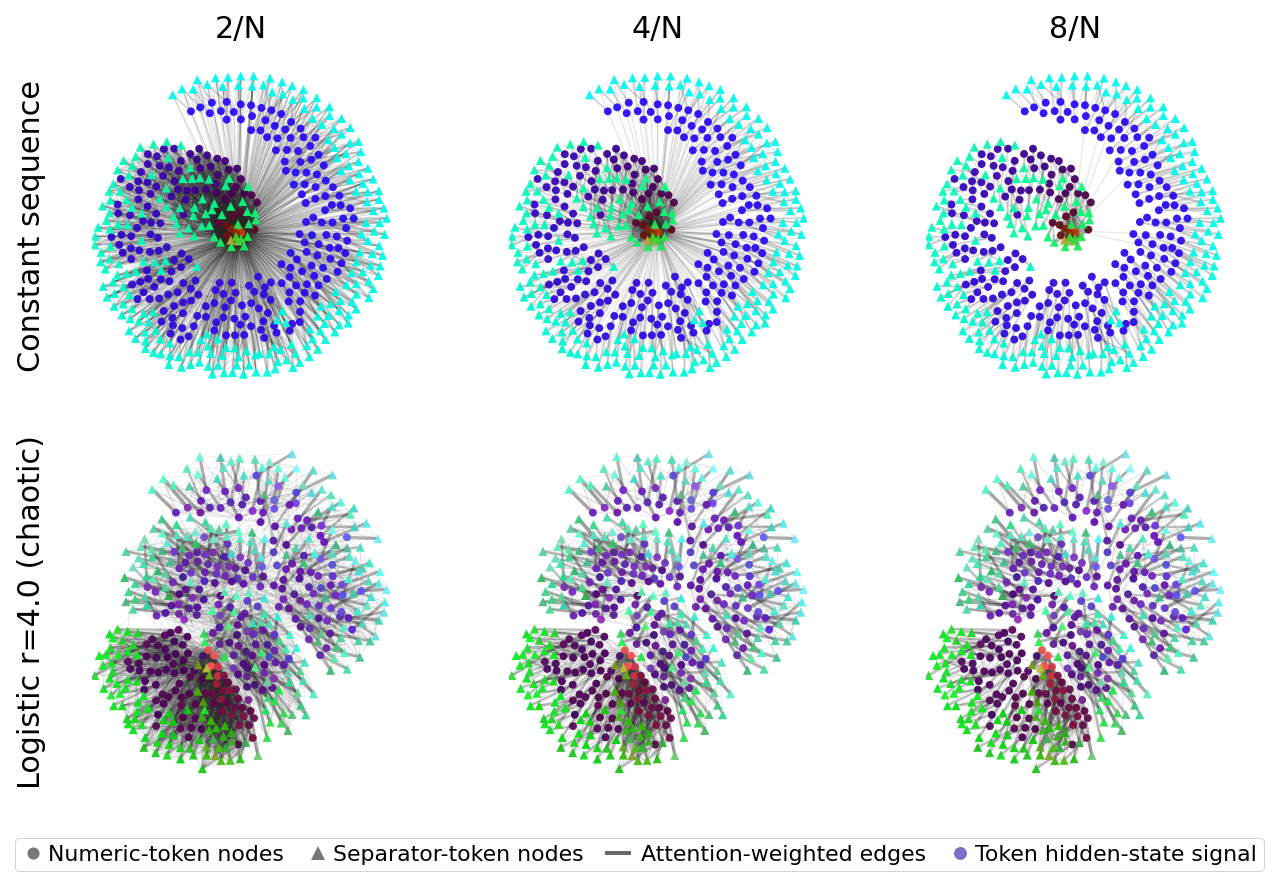

In [5]:
# The included caches contain the constant and chaotic logistic examples
check_processed_graph_data()
LAYER_INDEX = int(available_layer_indices()[-1])

plot_last_layer_threshold_robustness(
    layer_index=LAYER_INDEX,
    frac=CONTEXT_FRAC,
    save=True,
    show=True,
);